# Risco de Crédito: KNN x Árvore de Decisão

Projeto avaliativo do Módulo 1 (Machine Learning e Visão Computacional, T3).

Escolhi a Opção A, a base `credit_risk_dataset.csv`, com 32.581 pedidos de empréstimo e 12 colunas.

O banco quer saber, antes de liberar o empréstimo, se o cliente vai ficar inadimplente (`loan_status = 1`) ou
pagar em dia (`loan_status = 0`). O modelo pode errar de dois jeitos:

- Falso positivo: marca como arriscado um cliente que pagaria. O banco recusa e deixa de ganhar os juros.
- Falso negativo: marca como seguro um cliente que não paga. O banco empresta e perde o dinheiro.

O notebook segue as 6 fases do enunciado. Fui explicando cada decisão nas células de texto.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTENC

import os
SEED = 42                      # semente fixa para dar sempre o mesmo resultado
FIG_DIR = "reports/figures"    # salvo os gráficos aqui para usar no README
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## Fase 1: Análise Exploratória de Dados (EDA)

### 1.1 Descritiva e estatística

In [2]:
df_raw = pd.read_csv("data/credit_risk_dataset.csv")
df = df_raw.copy()

print(f"Tamanho da base: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
df.head()

Tamanho da base: 32,581 linhas x 12 colunas


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.00,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.00,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.00,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.00,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.00,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
# tipos das colunas e quantos valores não nulos cada uma tem
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [4]:
# estatísticas das colunas numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,"32,581.00",27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,"32,581.00","66,074.85","61,983.12","4,000.00","38,500.00","55,000.00","79,200.00","6,000,000.00"
person_emp_length,"31,686.00",4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,"32,581.00","9,589.37","6,322.09",500.00,"5,000.00","8,000.00","12,200.00","35,000.00"
loan_int_rate,"29,465.00",11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,"32,581.00",0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,"32,581.00",0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,"32,581.00",5.80,4.06,2.00,3.00,4.00,8.00,30.00


In [5]:
# e das categóricas
df.describe(include="object").T

,count,unique,top,freq
person_home_ownership,32581,4,RENT,16446
loan_intent,32581,6,EDUCATION,6453
loan_grade,32581,7,A,10777
cb_person_default_on_file,32581,2,N,26836


In [6]:
# nulos, duplicadas e proporção do alvo
print("Valores nulos por coluna:")
print(df.isna().sum()[df.isna().sum() > 0], "\n")
print(f"Linhas duplicadas: {df.duplicated().sum()}\n")
print("Distribuição do alvo (loan_status):")
print(df["loan_status"].value_counts(normalize=True).mul(100).round(2).astype(str) + " %")

Valores nulos por coluna:
person_emp_length     895
loan_int_rate        3116
dtype: int64 

Linhas duplicadas: 165

Distribuição do alvo (loan_status):
loan_status
0    78.18 %
1    21.82 %
Name: proportion, dtype: str


In [7]:
# assimetria: perto de 0 é simétrica, acima de 1 tem cauda longa à direita
df.select_dtypes("number").drop(columns="loan_status").skew().sort_values(ascending=False).to_frame("skew")

,skew
person_income,32.87
person_emp_length,2.61
person_age,2.58
cb_person_cred_hist_length,1.66
loan_amnt,1.19
loan_percent_income,1.06
loan_int_rate,0.21


### 1.2 Análise visual

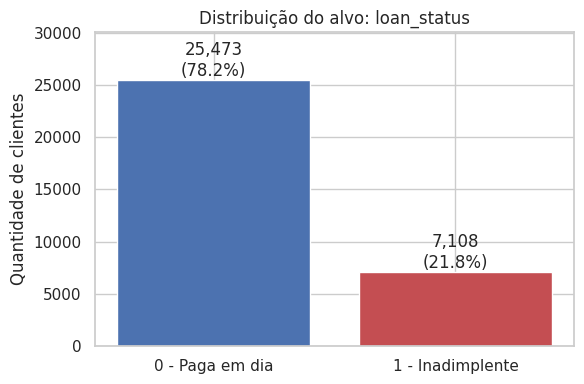

In [8]:
# gráfico 1: quantos clientes tem em cada classe
fig, ax = plt.subplots(figsize=(6, 4))
cont = df["loan_status"].value_counts().sort_index()
bars = ax.bar(["0 - Paga em dia", "1 - Inadimplente"], cont.values, color=["#4C72B0", "#C44E52"])
for b, v in zip(bars, cont.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / cont.sum():.1%})", ha="center", va="bottom")
ax.set_title("Distribuição do alvo: loan_status")
ax.set_ylabel("Quantidade de clientes")
ax.set_ylim(0, cont.max() * 1.18)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_alvo_desbalanceado.png", dpi=110); plt.show()

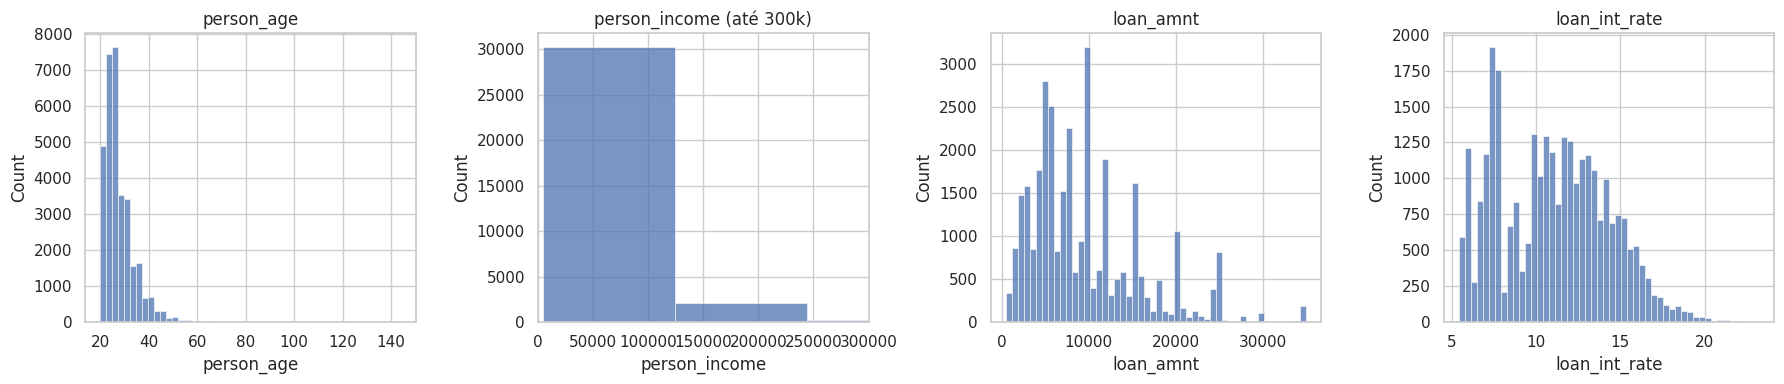

In [9]:
# gráfico 2: histogramas das principais numéricas
cols = ["person_age", "person_income", "loan_amnt", "loan_int_rate"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, cols):
    sns.histplot(df[c].dropna(), bins=50, ax=ax, color="#4C72B0")
    ax.set_title(c)
axes[1].set_xlim(0, 300_000)  # cortei em 300 mil, senão não dá para ver nada
axes[1].set_title("person_income (até 300k)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_histogramas.png", dpi=110); plt.show()

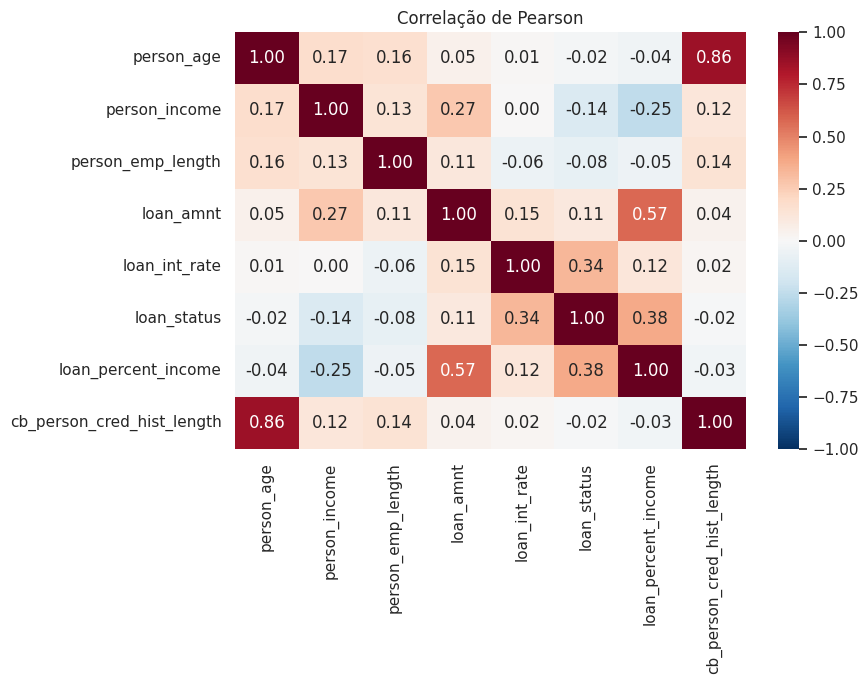

In [10]:
# gráfico 3: correlação de Pearson
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.select_dtypes("number").corr(method="pearson")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Pearson")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_correlacao.png", dpi=110); plt.show()

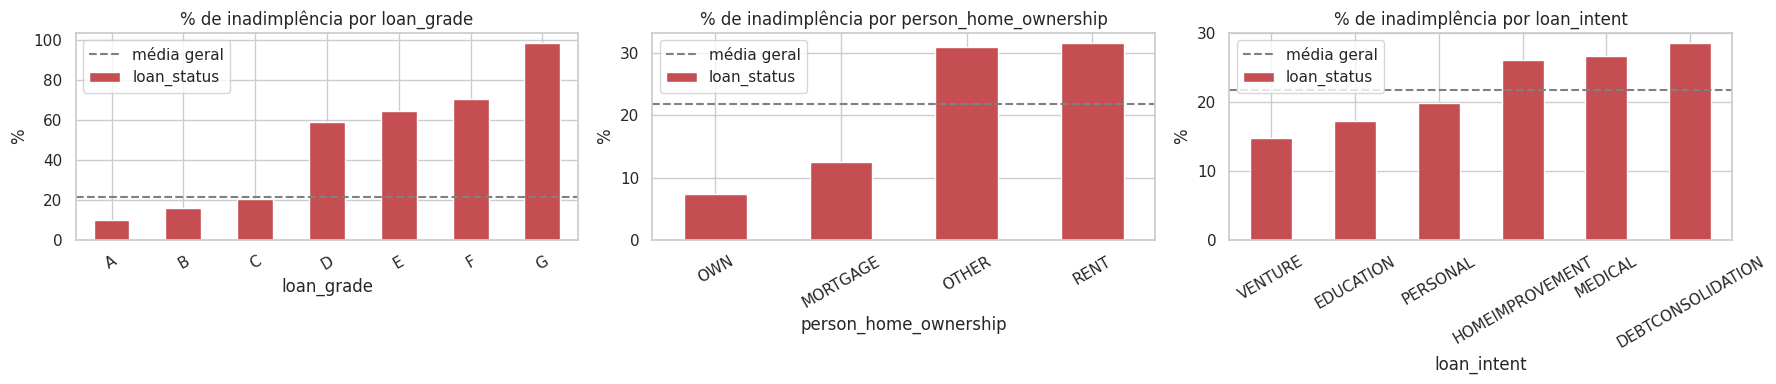

In [11]:
# gráfico 4: inadimplência por categoria (as categóricas não entram no Pearson)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, ["loan_grade", "person_home_ownership", "loan_intent"]):
    taxa = df.groupby(c)["loan_status"].mean().sort_values() if c != "loan_grade" \
        else df.groupby(c)["loan_status"].mean()
    taxa.mul(100).plot(kind="bar", ax=ax, color="#C44E52")
    ax.axhline(df["loan_status"].mean() * 100, ls="--", color="gray", label="média geral")
    ax.set_title(f"% de inadimplência por {c}"); ax.set_ylabel("%"); ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_inadimplencia_categorias.png", dpi=110); plt.show()

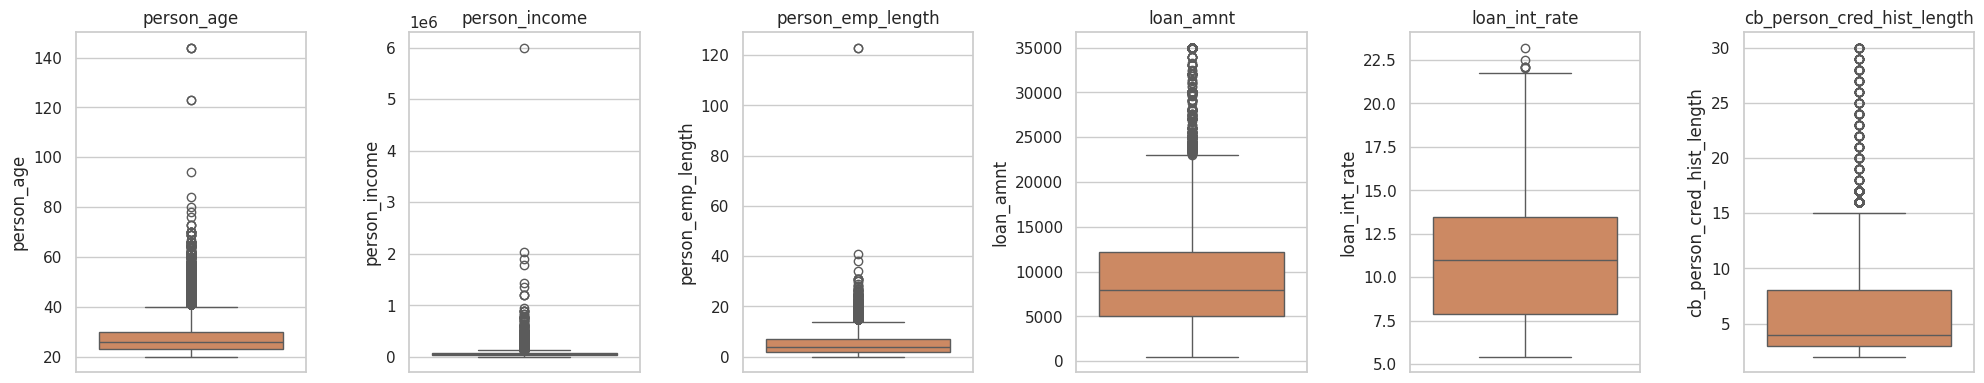

In [12]:
# gráfico 5: boxplots para ver os outliers
cols = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate", "cb_person_cred_hist_length"]
fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(y=df[c], ax=ax, color="#DD8452")
    ax.set_title(c)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_boxplots.png", dpi=110); plt.show()

### 1.3 Tomada de decisão: o que a EDA mostrou

A base tem 32.581 linhas e 12 colunas, sendo 8 numéricas e 4 categóricas.

O alvo é desbalanceado: 78,2% pagam em dia e 21,8% ficam inadimplentes. Se eu fizesse um modelo que aprova todo
mundo, ele teria 78% de acurácia e não serviria para nada. Então não vou me guiar pela acurácia. Vou olhar recall,
precisão e F1 da classe 1, e vou balancear as classes, mas só no treino.

No `describe` apareceram valores que não fazem sentido: idade de 144 anos e 123 anos de emprego. Isso é erro de
digitação. Já a renda vai até 6 milhões com mediana de 55 mil. Esse caso é diferente, porque deve ser gente que
ganha muito mesmo, mas uma cauda desse tamanho atrapalha o KNN e vou ter que tratar. Também tem nulos em
`loan_int_rate` (3.116) e em `person_emp_length` (895), além de 165 linhas duplicadas.

Nos gráficos, o que mais me chamou atenção:

- A coluna mais correlacionada com a inadimplência é `loan_percent_income` (0,38), que é quanto o empréstimo pesa
  na renda. Depois vem a taxa de juros (0,34). A renda tem correlação negativa (-0,14).
- O `loan_grade` parece uma escada: uns 10% de inadimplência no grau A e 98% no G.
- Quem aluga (RENT) tem uns 32% de inadimplência, e quem tem casa própria (OWN) fica em 7%.
- `person_age` e `cb_person_cred_hist_length` são bem correlacionadas entre si (0,86), o que é esperado. Deixei as
  duas porque não são a mesma coisa.

O que vou fazer a partir disso: tirar as duplicadas e as linhas com valores impossíveis, preencher os nulos
olhando a distribuição de cada coluna, tratar a cauda da renda só para o KNN, criar a coluna
`comprometimento_renda` e codificar o `loan_grade` respeitando a ordem de A até G.

## Fase 2: Tratamento e Limpeza (Data Prep)

### 2.1 Duplicadas
Linha repetida não acrescenta informação. E ainda tem o risco de a mesma linha cair no treino e no teste, o que
deixaria o resultado do teste melhor do que ele é de verdade. Removi todas.

In [13]:
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicadas removidas: {n_antes - len(df)}  |  Linhas restantes: {len(df):,}")

Duplicadas removidas: 165  |  Linhas restantes: 32,416


### 2.2 Valores impossíveis (erros de registro)
Antes de preencher os nulos, tirei as linhas com idade acima de 100 anos ou mais de 60 anos de emprego. Não são
outliers de verdade, são erros de cadastro, e se ficassem iam puxar a média que vou usar na imputação.

In [14]:
impossiveis = df[(df["person_age"] > 100) | (df["person_emp_length"] > 60)]
display(impossiveis[["person_age", "person_emp_length", "person_income", "loan_status"]])

df = df.drop(index=impossiveis.index).reset_index(drop=True)
print(f"Registros impossíveis removidos: {len(impossiveis)}  |  Linhas restantes: {len(df):,}")

,person_age,person_emp_length,person_income,loan_status
0,22,123.00,59000,1
81,144,4.00,250000,0
183,144,4.00,200000,0
210,21,123.00,192000,0
575,123,2.00,80004,0
747,123,7.00,78000,0
32132,144,12.00,6000000,0


Registros impossíveis removidos: 7  |  Linhas restantes: 32,409


### 2.3 Valores nulos
Para decidir entre média e mediana, olhei a assimetria de cada coluna que tem nulos:

In [15]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0]
resumo = pd.DataFrame({
    "nulos": nulos,
    "% da base": (nulos / len(df) * 100).round(2),
    "média": df[nulos.index].mean(),
    "mediana": df[nulos.index].median(),
    "assimetria (skew)": df[nulos.index].skew(),
})
resumo

,nulos,% da base,média,mediana,assimetria (skew)
person_emp_length,887,2.74,4.78,4.00,1.25
loan_int_rate,3094,9.55,11.02,10.99,0.21


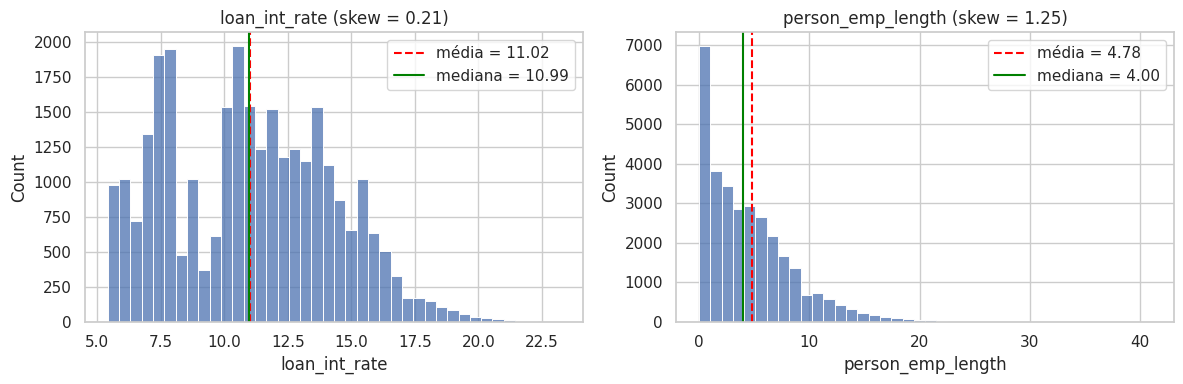

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, ["loan_int_rate", "person_emp_length"]):
    sns.histplot(df[c].dropna(), bins=40, ax=ax, color="#4C72B0")
    ax.axvline(df[c].mean(), color="red", ls="--", label=f"média = {df[c].mean():.2f}")
    ax.axvline(df[c].median(), color="green", ls="-", label=f"mediana = {df[c].median():.2f}")
    ax.set_title(f"{c} (skew = {df[c].skew():.2f})"); ax.legend()
plt.tight_layout(); plt.show()

Justificativa da imputação:

- `loan_int_rate`: usei a média. A distribuição é quase simétrica (skew de 0,21) e a média (11,02) é praticamente
  igual à mediana (10,99), então tanto faz, e a média é a escolha indicada para distribuição simétrica.
- `person_emp_length`: usei a mediana. A distribuição é assimétrica à direita (skew de 1,25). Tem muita gente com
  poucos anos de emprego e alguns com mais de 20, e esses poucos puxam a média para cima (4,78). A mediana (4,0)
  representa melhor o cliente comum e não sofre com os outliers.

In [17]:
media_juros = df["loan_int_rate"].mean()
mediana_emprego = df["person_emp_length"].median()

df["loan_int_rate"] = df["loan_int_rate"].fillna(media_juros)            # média
df["person_emp_length"] = df["person_emp_length"].fillna(mediana_emprego)  # mediana

print(f"loan_int_rate imputado com a média: {media_juros:.2f}")
print(f"person_emp_length imputado com a mediana: {mediana_emprego:.1f}")
print("Nulos restantes:", int(df.isna().sum().sum()))

loan_int_rate imputado com a média: 11.02
person_emp_length imputado com a mediana: 4.0
Nulos restantes: 0


### 2.4 Outliers
Contei os outliers de cada coluna numérica pelo critério do IQR (abaixo de Q1 - 1,5 x IQR ou acima de
Q3 + 1,5 x IQR):

In [18]:
cont_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
             "loan_int_rate", "cb_person_cred_hist_length"]
linhas = []
for c in cont_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    linhas.append({"variável": c, "outliers (IQR)": n_out, "% da base": n_out / len(df) * 100,
                   "p99": df[c].quantile(0.99), "máximo": df[c].max()})
pd.DataFrame(linhas).set_index("variável")

,outliers (IQR),% da base,p99,máximo
variável,,,,
person_age,1486,4.59,50.00,94.00
person_income,1474,4.55,"225,000.00","2,039,784.00"
person_emp_length,850,2.62,17.00,41.00
loan_amnt,1678,5.18,"29,792.00","35,000.00"
loan_int_rate,70,0.22,18.39,23.22
cb_person_cred_hist_length,1138,3.51,17.00,30.00


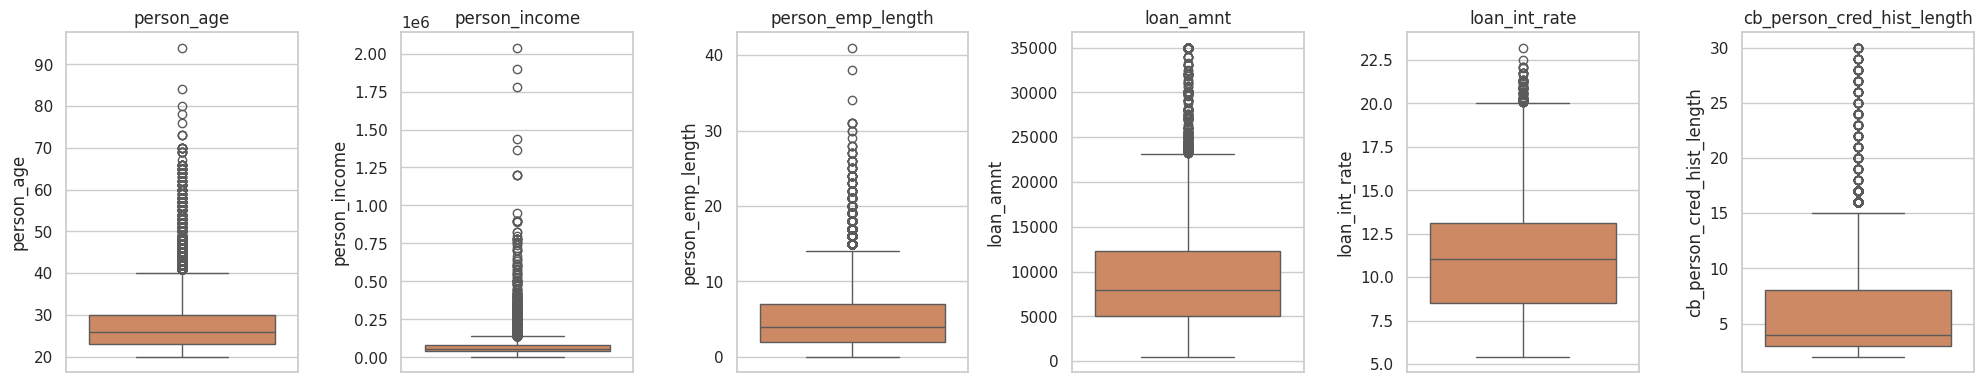

In [19]:
# boxplots de novo, agora sem os valores impossíveis
fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, c in zip(axes, cont_cols):
    sns.boxplot(y=df[c], ax=ax, color="#DD8452"); ax.set_title(c)
plt.tight_layout(); plt.show()

Decisão de tratamento (diferente para cada modelo):

1. O que era erro (idade acima de 100, emprego acima de 60 anos) eu já removi no item 2.2.
2. O resto eu mantive. Pelo IQR daria para marcar milhares de linhas, tipo 1.470 rendas altas e 1.680 empréstimos
   grandes, mas são clientes reais. Se eu apagasse, o modelo não ia aprender nada sobre os contratos de valor mais
   alto, que são justamente os que mais importam para o banco.
3. Na Árvore de Decisão não mexi em nada. Ela separa os dados com cortes do tipo "renda <= X", então uma renda de
   2 milhões cai do mesmo lado que uma de 200 mil. O valor extremo não muda o corte.
4. No KNN é diferente, porque ele calcula distância entre os clientes. Uma renda de 2 milhões fica muito longe de
   todo mundo e acaba mandando na distância, mesmo depois do `StandardScaler` (a média e o desvio também são
   puxados pela cauda). Por isso, só nos dados do KNN, vou limitar os valores entre os percentis 1 e 99
   (clipping). Os limites são calculados só no treino, lá na Fase 4, para não vazar nada do teste.

## Fase 3: Feature Engineering (Coluna Calculada)

Criei a coluna `comprometimento_renda = (loan_amnt / person_income) * 100`, que é quanto da renda anual o
empréstimo representa, em porcentagem. Na EDA esse foi o fator mais ligado à inadimplência.

Antes de dividir, conferi duas coisas: `loan_amnt` e `person_income` não têm nulos, e a menor renda da base é
4.000, então não tem divisão por zero. Deixei os `assert` no código para garantir.

In [20]:
# confiro antes de dividir: sem nulos e sem renda zero
assert df[["loan_amnt", "person_income"]].isna().sum().sum() == 0, "Há nulos nas colunas de origem"
assert (df["person_income"] > 0).all(), "Há renda zero/negativa -> divisão inválida"

df["comprometimento_renda"] = (df["loan_amnt"] / df["person_income"]) * 100

assert np.isfinite(df["comprometimento_renda"]).all()
df[["loan_amnt", "person_income", "comprometimento_renda", "loan_percent_income"]].head()

,loan_amnt,person_income,comprometimento_renda,loan_percent_income
0,1000,9600,10.42,0.10
1,5500,9600,57.29,0.57
2,35000,65500,53.44,0.53
3,35000,54400,64.34,0.55
4,2500,9900,25.25,0.25


count   32,409.00
mean        17.06
std         10.71
min          0.08
25%          8.97
50%         14.81
75%         22.92
max         83.00
Name: comprometimento_renda, dtype: float64 

Correlação com o alvo:
comprometimento_renda   0.39
loan_percent_income     0.38
loan_status             1.00
Name: loan_status, dtype: float64

Correlação entre a nova coluna e loan_percent_income: 0.9989


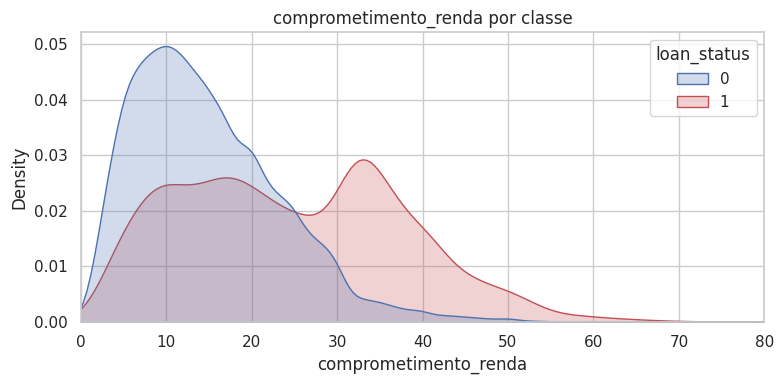

In [21]:
print(df["comprometimento_renda"].describe(), "\n")
print("Correlação com o alvo:")
print(df[["comprometimento_renda", "loan_percent_income", "loan_status"]].corr()["loan_status"].round(3))
print("\nCorrelação entre a nova coluna e loan_percent_income:",
      round(df["comprometimento_renda"].corr(df["loan_percent_income"]), 4))

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=df, x="comprometimento_renda", hue="loan_status", common_norm=False, fill=True, ax=ax,
            palette={0: "#4C72B0", 1: "#C44E52"})
ax.set_xlim(0, 80); ax.set_title("comprometimento_renda por classe")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/06_comprometimento_renda.png", dpi=110); plt.show()

A coluna nova ficou com a maior correlação com o alvo da base inteira (0,39). No gráfico dá para ver que os
inadimplentes comprometem uma parte bem maior da renda.

Só que a coluna original `loan_percent_income` é a mesma conta, arredondada em duas casas (correlação de 0,999
entre as duas). Se eu deixasse as duas, o KNN contaria essa informação em dobro na distância. Fiquei com a que eu
calculei, que é mais precisa, e removi a `loan_percent_income`.

In [22]:
df = df.drop(columns="loan_percent_income")
print("Colunas finais:", list(df.columns))

Colunas finais: ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'comprometimento_renda']


## Fase 4: Separação, Balanceamento e Escalonamento Seguro

### 4.1 Encoding
- `loan_grade`: codifiquei em ordem (A=0 até G=6). Como o risco aumenta de A para G, faz sentido manter essa ordem
  em uma coluna só.
- `cb_person_default_on_file`: virou 0 e 1 (Y=1, N=0).
- `person_home_ownership` e `loan_intent`: One-Hot Encoding. Aqui não existe ordem (alugar não é "maior" que
  financiar). Se eu colocasse números, o KNN ia entender que uma categoria está mais perto da outra, o que não é
  verdade.

In [23]:
df_model = df.copy()
df_model["loan_grade"] = df_model["loan_grade"].map({g: i for i, g in enumerate("ABCDEFG")})
df_model["cb_person_default_on_file"] = (df_model["cb_person_default_on_file"] == "Y").astype(int)
df_model = pd.get_dummies(df_model, columns=["person_home_ownership", "loan_intent"], dtype=int)

print(f"Shape após encoding: {df_model.shape}")
df_model.head()

Shape após encoding: (32409, 20)


,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_status,cb_person_default_on_file,cb_person_cred_hist_length,comprometimento_renda,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,21,9600,5.00,1,1000,11.14,0,0,2,10.42,0,0,1,0,0,1,0,0,0,0
1,25,9600,1.00,2,5500,12.87,1,0,3,57.29,1,0,0,0,0,0,0,1,0,0
2,23,65500,4.00,2,35000,15.23,1,0,2,53.44,0,0,0,1,0,0,0,1,0,0
3,24,54400,8.00,2,35000,14.27,1,1,4,64.34,0,0,0,1,0,0,0,1,0,0
4,21,9900,2.00,0,2500,7.14,1,0,2,25.25,0,0,1,0,0,0,0,0,0,1


### 4.2 Split estratificado (80/20)

In [24]:
X = df_model.drop(columns="loan_status")
y = df_model["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f"Treino: {X_train.shape}  |  Teste: {X_test.shape}")
print(pd.DataFrame({
    "Base completa": y.value_counts(normalize=True),
    "Treino": y_train.value_counts(normalize=True),
    "Teste": y_test.value_counts(normalize=True),
}).mul(100).round(2).astype(str) + " %")

Treino: (25927, 19)  |  Teste: (6482, 19)
            Base completa   Treino    Teste
loan_status                                
0                 78.13 %  78.13 %  78.12 %
1                 21.87 %  21.87 %  21.88 %


Com o `stratify=y`, treino e teste ficaram com a mesma proporção de inadimplentes (21,9%).

### 4.3 Balanceamento: SMOTE só no treino
Usei o SMOTENC, que é o SMOTE para bases com colunas numéricas e categóricas misturadas. Nas numéricas ele cria
clientes inadimplentes novos entre vizinhos parecidos. Nas categóricas ele copia o valor mais comum entre os
vizinhos, então não aparece coisa sem sentido como "0,37 de RENT".

O `fit_resample` roda só no `X_train`. O teste fica como veio, com 78/22, que é a proporção real. Se eu
balanceasse antes de separar, clientes sintéticos criados a partir de clientes do teste iriam parar no treino. Aí
o modelo já teria visto o teste e o resultado ficaria melhor do que é de verdade (vazamento de dados).

In [25]:
cont_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
             "loan_int_rate", "cb_person_cred_hist_length", "comprometimento_renda"]
cat_idx = [i for i, c in enumerate(X_train.columns) if c not in cont_cols]

smote = SMOTENC(categorical_features=cat_idx, random_state=SEED)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)   # só no treino

print("Treino ANTES do SMOTE:", y_train.value_counts().to_dict())
print("Treino DEPOIS do SMOTE:", y_train_bal.value_counts().to_dict())
print("Teste (intocado):     ", y_test.value_counts().to_dict())

Treino ANTES do SMOTE: {0: 20257, 1: 5670}
Treino DEPOIS do SMOTE: {0: 20257, 1: 20257}
Teste (intocado):      {0: 5064, 1: 1418}


### 4.4 Escalonamento seguro: somente para o KNN
Fiz uma cópia dos dados só para o KNN. Nela, as colunas contínuas passam por duas coisas:

1. clipping entre os percentis 1 e 99 (a decisão de outliers da Fase 2), com os limites calculados no treino;
2. `StandardScaler`, com `fit_transform` no treino balanceado e só `transform` no teste.

As colunas 0/1 e o `loan_grade` eu não escalonei. Também apliquei o mesmo scaler no treino original (sem SMOTE),
porque vou usar ele na Fase 5 para medir o desempenho de treino.

In [26]:
# limites do clipping calculados no treino
lim_inf = X_train_bal[cont_cols].quantile(0.01)
lim_sup = X_train_bal[cont_cols].quantile(0.99)

def clip_knn(Z):
    Z = Z.copy()
    Z[cont_cols] = Z[cont_cols].clip(lower=lim_inf, upper=lim_sup, axis=1)
    return Z

scaler = StandardScaler()

X_train_bal_knn = clip_knn(X_train_bal)
X_train_bal_knn[cont_cols] = scaler.fit_transform(X_train_bal_knn[cont_cols])   # fit só no treino

X_test_knn = clip_knn(X_test)
X_test_knn[cont_cols] = scaler.transform(X_test_knn[cont_cols])                  # no teste só transform

X_train_knn = clip_knn(X_train)
X_train_knn[cont_cols] = scaler.transform(X_train_knn[cont_cols])                # treino original também só transform

print("Médias no treino balanceado (≈0) e desvios (≈1) após o scaler:")
display(X_train_bal_knn[cont_cols].agg(["mean", "std"]).T.round(3))

Médias no treino balanceado (≈0) e desvios (≈1) após o scaler:


,mean,std
person_age,0.00,1.00
person_income,0.00,1.00
person_emp_length,0.00,1.00
loan_amnt,-0.00,1.00
loan_int_rate,-0.00,1.00
cb_person_cred_hist_length,0.00,1.00
comprometimento_renda,-0.00,1.00


E a Árvore de Decisão? Ela treina com o `X_train_bal` direto, sem clipping e sem scaler. Como a árvore só faz
cortes do tipo "`person_income` <= 38.500?", mudar a escala de uma coluna muda o número do corte, mas não muda
quem fica de cada lado. Para provar, treinei a mesma árvore com e sem escala e comparei as previsões:

In [27]:
arv_bruta = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(X_train_bal, y_train_bal)

sc_tmp = StandardScaler().fit(X_train_bal)
arv_escalada = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(sc_tmp.transform(X_train_bal), y_train_bal)

iguais = (arv_bruta.predict(X_test) == arv_escalada.predict(sc_tmp.transform(X_test))).mean()
print(f"Previsões idênticas entre árvore sem escala e com escala: {iguais:.2%}")

Previsões idênticas entre árvore sem escala e com escala: 100.00%


## Fase 5: Modelagem e Validação (O Desafio do Overfitting)

Como medi o treino: os modelos são treinados no treino balanceado, mas as métricas de treino eu calculei no treino
original, sem os clientes sintéticos. Fiz assim porque a precisão muda conforme a proporção das classes. Se eu
comparasse um treino 50/50 com um teste 78/22, a diferença entre os dois não seria só overfitting. Desse jeito os
dois têm a mesma proporção.

A métrica que usei para escolher foi o F1 da classe 1 (inadimplente) no teste, porque ele junta recall e precisão.
Para ver overfitting, olhei a diferença entre o F1 do treino e o do teste (chamei de gap).

In [28]:
def avaliar(modelo, X_, y_):
    pred = modelo.predict(X_)
    prob = modelo.predict_proba(X_)[:, 1]
    return {"Acurácia": accuracy_score(y_, pred), "Precisão": precision_score(y_, pred),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred), "AUC": roc_auc_score(y_, prob)}

def tabela(resultados, param):
    t = pd.DataFrame(resultados).set_index(param)
    t["Gap F1 (treino − teste)"] = t["F1 treino"] - t["F1 teste"]
    return t

### 5.1 Otimização do KNN: variando `n_neighbors` (K)

In [29]:
valores_k = [3, 5, 7, 9, 15, 25]
res_knn = []
for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_bal_knn, y_train_bal)   # dados escalonados
    tr, te = avaliar(knn, X_train_knn, y_train), avaliar(knn, X_test_knn, y_test)
    res_knn.append({"K": k, "Recall treino": tr["Recall"], "Recall teste": te["Recall"],
                    "F1 treino": tr["F1"], "F1 teste": te["F1"], "AUC treino": tr["AUC"], "AUC teste": te["AUC"]})

tab_knn = tabela(res_knn, "K")
tab_knn.style.format("{:.3f}").highlight_max(subset=["F1 teste"], color="#c8e6c9")

,Recall treino,Recall teste,F1 treino,F1 teste,AUC treino,AUC teste,Gap F1 (treino − teste)
K,,,,,,,
3,0.801,0.696,0.830,0.701,0.973,0.854,0.129
5,0.765,0.701,0.792,0.704,0.958,0.869,0.088
7,0.753,0.708,0.774,0.711,0.948,0.876,0.063
9,0.750,0.714,0.766,0.717,0.941,0.880,0.050
15,0.748,0.717,0.748,0.710,0.928,0.887,0.038
25,0.749,0.736,0.732,0.710,0.917,0.890,0.022


### 5.2 Otimização da Árvore: variando `max_depth`

In [30]:
profundidades = [3, 5, 7, 9, 12, None]
res_arv = []
for d in profundidades:
    arv = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train_bal, y_train_bal)  # dados sem escala
    tr, te = avaliar(arv, X_train, y_train), avaliar(arv, X_test, y_test)
    res_arv.append({"max_depth": "None" if d is None else d,
                    "Recall treino": tr["Recall"], "Recall teste": te["Recall"],
                    "F1 treino": tr["F1"], "F1 teste": te["F1"], "AUC treino": tr["AUC"], "AUC teste": te["AUC"],
                    "Folhas": arv.get_n_leaves()})

tab_arv = tabela(res_arv, "max_depth")
tab_arv.style.format({c: "{:.3f}" for c in tab_arv.columns if c != "Folhas"}) \
       .highlight_max(subset=["F1 teste"], color="#c8e6c9")

,Recall treino,Recall teste,F1 treino,F1 teste,AUC treino,AUC teste,Folhas,Gap F1 (treino − teste)
max_depth,,,,,,,,
3,0.729,0.742,0.735,0.740,0.848,0.854,8,-0.004
5,0.709,0.726,0.747,0.762,0.883,0.888,27,-0.015
7,0.686,0.696,0.801,0.807,0.898,0.896,66,-0.006
9,0.743,0.738,0.794,0.779,0.915,0.903,145,0.015
12,0.781,0.754,0.802,0.764,0.940,0.903,376,0.039
None,1.000,0.776,1.000,0.751,1.000,0.847,2501,0.249


### 5.3 Diagnóstico visual: curvas de treino x teste

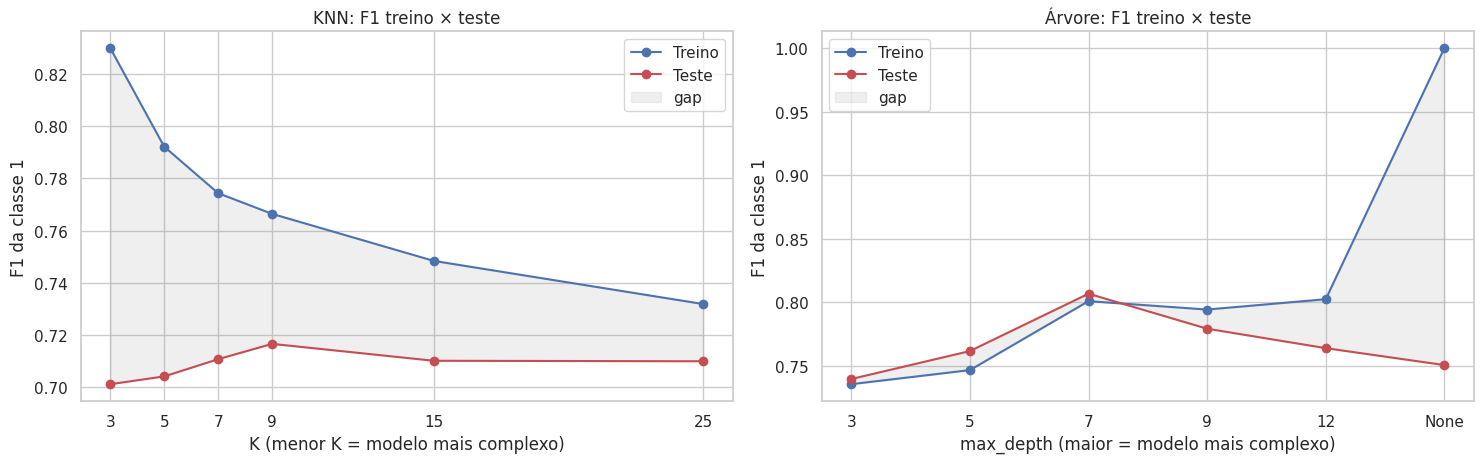

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

ax = axes[0]
ax.plot(valores_k, tab_knn["F1 treino"], "o-", label="Treino", color="#4C72B0")
ax.plot(valores_k, tab_knn["F1 teste"], "o-", label="Teste", color="#C44E52")
ax.fill_between(valores_k, tab_knn["F1 teste"], tab_knn["F1 treino"], alpha=0.12, color="gray", label="gap")
ax.set_xticks(valores_k); ax.set_xlabel("K (menor K = modelo mais complexo)")
ax.set_ylabel("F1 da classe 1"); ax.set_title("KNN: F1 treino × teste"); ax.legend()

ax = axes[1]
x_lab = [str(d) for d in tab_arv.index]
ax.plot(x_lab, tab_arv["F1 treino"], "o-", label="Treino", color="#4C72B0")
ax.plot(x_lab, tab_arv["F1 teste"], "o-", label="Teste", color="#C44E52")
ax.fill_between(x_lab, tab_arv["F1 teste"], tab_arv["F1 treino"], alpha=0.12, color="gray", label="gap")
ax.set_xlabel("max_depth (maior = modelo mais complexo)")
ax.set_ylabel("F1 da classe 1"); ax.set_title("Árvore: F1 treino × teste"); ax.legend()

plt.tight_layout(); plt.savefig(f"{FIG_DIR}/07_overfitting.png", dpi=110); plt.show()

In [32]:
# pego a configuração com maior F1 no teste
melhor_k = int(tab_knn["F1 teste"].idxmax())
melhor_d_label = tab_arv["F1 teste"].idxmax()
melhor_d = None if melhor_d_label == "None" else int(melhor_d_label)
print(f"Melhor KNN:    K = {melhor_k}  (F1 teste = {tab_knn.loc[melhor_k, 'F1 teste']:.3f}, "
      f"gap = {tab_knn.loc[melhor_k, 'Gap F1 (treino − teste)']:.3f})")
print(f"Melhor Árvore: max_depth = {melhor_d_label}  (F1 teste = {tab_arv.loc[melhor_d_label, 'F1 teste']:.3f}, "
      f"gap = {tab_arv.loc[melhor_d_label, 'Gap F1 (treino − teste)']:.3f})")

Melhor KNN:    K = 9  (F1 teste = 0.717, gap = 0.050)
Melhor Árvore: max_depth = 7  (F1 teste = 0.807, gap = -0.006)


### 5.4 Diagnóstico de overfitting

Árvore: com `max_depth=None` ela cresce até separar praticamente cada cliente (2.501 folhas). O F1 no treino dá
1,000, ou seja, decorou tudo, e no teste cai para 0,75. É um gap de 0,25, overfitting bem claro. Com profundidade
12 o gap já começa a aparecer (0,04) e o teste fica pior do que com 7. No outro extremo, com 3 e 5 quase não tem
gap, mas o F1 é mais baixo, porque o modelo está simples demais. A melhor foi `max_depth = 7`: maior F1 no teste
(0,81) e gap praticamente zero.

KNN: aqui é ao contrário, quanto menor o K mais complexo o modelo. Com K = 3 a previsão depende de só 3 vizinhos
e o modelo acaba pegando ruído do treino: F1 de 0,83 no treino e 0,70 no teste (gap de 0,13). Aumentando o K o gap
vai diminuindo. O melhor F1 de teste foi com K = 9 (0,72, gap de 0,05). De 15 em diante o gap continua caindo, mas
o teste não melhora mais. Fiquei com K = 9.

Uma observação: escolhi os hiperparâmetros comparando treino e teste, como o enunciado pede. Sei que em um projeto
real o certo seria fazer essa escolha com validação cruzada dentro do treino e deixar o teste só para a avaliação
final.